<a href="https://colab.research.google.com/github/Decoding-Data-Science/CommunityWorkshops/blob/main/MC14_MultiAgent_SOC_Team_LangGraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MC 14: From One SOC Assistant to a Coordinated AI Team
### Building Multi-Agent AI Systems with LangGraph

**Instructor:** Mohammad Arshad Ahmed · Decoding Data Science, AI Residency

In MC 13 we built **one** SOC Assistant with two tools. Today we grow it into a **team**:

| Agent | Job | Tool it can use |
|---|---|---|
| Log Analyst | Find out what actually happened | `query_security_logs` |
| Playbook Analyst | Find the rules that apply | `security_playbook` |
| Reviewer | Combine the evidence into one incident report | none (reasoning only) |

A **supervisor** routes work between them, everyone reads and writes a **shared state**,
a **retry policy** absorbs failures, and a **human approves the report** before it is final.

We reuse the exact same synthetic energy-plant incident from MC 13, so you can compare
the single agent and the team on the same case.

## Step 0: Add your OpenAI key to Colab Secrets (one time only)

1. Click the **key icon** on the left sidebar of Colab.
2. Click **+ Add new secret**.
3. In **Name**, type exactly: `OPENAI_API_KEY`
4. In **Value**, paste your OpenAI key (it starts with `sk-`).
5. Switch **Notebook access** ON.

## Step 1: Install the libraries (about 1 minute)

In [ ]:
# langchain        -> agent framework (create_agent lives here)
# langchain-openai -> lets LangChain talk to OpenAI models
# langgraph        -> state, nodes, edges, routing, memory, retries, human approval
!pip install -q -U "langchain>=1.0" "langchain-openai>=1.0" "langgraph>=1.0" langchain-text-splitters langchain_openai langchain_text_splitters

## Step 2: Load the API key from Colab Secrets

In [1]:
import os
from google.colab import userdata

try:
    os.environ["OPENAI_API_KEY"] = userdata.get("openai")
    print("OpenAI key loaded from Colab Secrets.")
except userdata.SecretNotFoundError:
    print("No secret called OPENAI_API_KEY found. Go back to Step 0 and add it.")
except userdata.NotebookAccessError:
    print("The secret exists, but Notebook access is OFF. Switch it ON in the key panel.")

MODEL = "gpt-4.1-mini"   # fast, low-cost model

OpenAI key loaded from Colab Secrets.


## Step 3: The same incident as MC 13

Same synthetic data: normal background noise plus one hidden incident on the night of 9-10 October
(failed logins, a service-account login, an IT-to-OT jump, a USB mount, and a pump setpoint change).

In [2]:
import sqlite3
import random

random.seed(13)   # same random data every time we run

# --- 1. Normal background activity (the "noise" a SOC sees every day) ---
hosts = ["ENG-WS-03", "ENG-WS-07", "HR-LT-21", "FIN-LT-08", "OPS-WS-02"]
users = ["a.khan", "o.haddad", "r.sharma", "p.patel", "m.chen"]
normal_events = [
    ("auth",     "login_success",      "Low",    "Normal login"),
    ("auth",     "login_failed",       "Low",    "Wrong password"),
    ("firewall", "connection_blocked", "Medium", "Blocked inbound scan"),
    ("endpoint", "av_detection",       "Medium", "Adware quarantined"),
]

rows = []
for i in range(400):
    source, event_type, severity, details = random.choice(normal_events)
    hour, minute = random.randint(0, 23), random.randint(0, 59)
    timestamp = f"2026-10-09 {hour:02d}:{minute:02d}:00"
    rows.append((timestamp, source, random.choice(hosts), random.choice(users), "10.10.4.21", "IT", event_type, severity, details))

# --- 2. The incident on the night of 9 to 10 October ---
attacker_ip = "45.155.205.99"   # an external IP address
for n in range(1, 7):           # six failed logins in a row
    rows.append((f"2026-10-10 01:4{n}:00", "auth", "ENG-WS-07", "svc_historian", attacker_ip, "IT", "login_failed", "Low", f"Wrong password (attempt {n})"))

rows += [
    ("2026-10-10 01:52:05", "auth",       "ENG-WS-07", "svc_historian", attacker_ip,  "IT", "login_success",      "Medium", "Interactive login by service account"),
    ("2026-10-10 01:58:12", "firewall",   "JMP-02",    "svc_historian", "10.10.4.37", "OT", "connection_allowed", "Low",    "IT to OT session via jump host"),
    ("2026-10-10 02:03:44", "endpoint",   "ENG-WS-07", "svc_historian", "10.10.4.37", "IT", "usb_mounted",        "Medium", "USB storage device mounted"),
    ("2026-10-10 02:09:27", "ot_monitor", "PLC-CW-01", "svc_historian", "10.10.4.37", "OT", "plc_write",          "High",   "Write command to cooling-water pump controller"),
    ("2026-10-10 02:11:03", "historian",  "A-001",     "svc_historian", "10.10.4.37", "OT", "setpoint_change",    "High",   "Pump A-001 speed changed 1450 to 1720 rpm"),
]

# --- 3. Save everything into a SQLite database file called soc.db ---
con = sqlite3.connect("soc.db")
con.execute("DROP TABLE IF EXISTS security_events")
con.execute("""CREATE TABLE security_events (
    timestamp TEXT, source TEXT, host TEXT, user TEXT,
    src_ip TEXT, zone TEXT, event_type TEXT, severity TEXT, details TEXT)""")
con.executemany("INSERT INTO security_events VALUES (?,?,?,?,?,?,?,?,?)", rows)
con.commit()
con.close()
print(f"Created soc.db with {len(rows)} security events")

Created soc.db with 411 security events


In [17]:
normal_events

[('auth', 'login_success', 'Low', 'Normal login'),
 ('auth', 'login_failed', 'Low', 'Wrong password'),
 ('firewall', 'connection_blocked', 'Medium', 'Blocked inbound scan'),
 ('endpoint', 'av_detection', 'Medium', 'Adware quarantined')]

## Step 4: The incident-response playbook (same document as MC 13)

In [3]:
PLAYBOOK = """
SOC-PB-001  Incident Response Playbook (Energy Plant)

1. Severity levels
Low: review in daily triage. Medium: investigate within 4 hours.
High: investigate within 30 minutes. Critical: respond immediately and page the OT on-call engineer.

2. Brute force
Five or more failed logins for the same account within 10 minutes is a suspected brute force attack.
If a successful login follows the failed attempts, treat it as a suspected credential compromise (High).
Logins from external IP addresses to internal workstations raise severity by one level.

3. Service accounts
Service accounts (names starting with svc_) must never log in interactively. Any interactive login by a service account is High.

4. IT to OT access
IT to OT access is only allowed through the jump host JMP-02, during maintenance windows:
Tuesday and Thursday, 10:00 to 14:00. Any IT to OT session outside a maintenance window is High.

5. USB devices
USB storage is not allowed on engineering workstations (ENG-WS-*). A USB mount on these hosts is Medium, or High if combined with other alerts.

6. OT changes
Any PLC write or setpoint change outside a maintenance window is Critical. Page the OT on-call engineer and verify with plant operations.

7. Containment
Isolating a host, disabling an account or blocking an IP needs approval from the SOC lead.
OT assets must never be isolated or shut down without approval from plant operations.
Never delete or change logs during an investigation.
"""
print("Playbook loaded:", len(PLAYBOOK), "characters")

Playbook loaded: 1467 characters


## Step 5: The same two tools, unchanged from MC 13

Each specialist will get **only the tool it needs**. That is one of the points of a team:
the Log Analyst can never touch the playbook, the Playbook Analyst can never run SQL.

In [6]:
from langchain_core.tools import tool
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

# 1. Cut the playbook into small chunks
splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)
chunks = splitter.split_documents([Document(page_content=PLAYBOOK)])

# 2. Turn each chunk into numbers (embeddings) and store them so we can search by meaning
store = InMemoryVectorStore.from_documents(chunks, OpenAIEmbeddings(model="text-embedding-3-small"))
print(f"Playbook split into {len(chunks)} searchable chunks")

# 3. The tool: find the 3 most relevant chunks for a question
@tool
def security_playbook(question: str) -> str:
    """Search the SOC incident-response playbook for rules: severity, brute force,
    service accounts, IT to OT access, maintenance windows, USB, OT changes, containment."""
    results = store.similarity_search(question, k=3)
    return "\n---\n".join(doc.page_content for doc in results)

Playbook split into 5 searchable chunks


In [7]:
@tool
def query_security_logs(sql: str) -> str:
    """Run ONE read-only SQL SELECT query on the security logs.
    Table: security_events(timestamp, source, host, user, src_ip, zone, event_type, severity, details).
    timestamp format: 'YYYY-MM-DD HH:MM:SS'. Use this for what actually happened."""

    # Guard 1: only allow a single SELECT query
    query = sql.strip().rstrip(";")
    blocked_words = ["insert", "update", "delete", "drop", "alter", "create"]
    if not query.lower().startswith("select") or ";" in query or any(w in query.lower() for w in blocked_words):
        return "REJECTED: only one read-only SELECT query is allowed."

    # Guard 2: open the database in read-only mode
    con = sqlite3.connect("file:soc.db?mode=ro", uri=True)
    try:
        rows = con.execute(query).fetchall()
        return str(rows[:30]) if rows else "No rows found."
    except Exception as error:
        return f"SQL error: {error}"
    finally:
        con.close()

## Step 6: The MC 13 version - one agent with both tools

This is where we finished last time. One agent holds both tools and decides everything itself.
Keep it: at the end we will run the same question through both designs and compare.

In [8]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

llm = ChatOpenAI(model=MODEL, temperature=0)

MC13_PROMPT = """You are the SOC Assistant for an energy plant.
- Use security_playbook for rules. Never invent rules.
- Use query_security_logs to see what actually happened.
- For an investigation: build a timeline, check each event against the playbook,
  give an overall severity, and list next steps with who must approve them.
- Always show evidence (times, hosts, users).
- You are READ-ONLY. You can only recommend."""

single_agent = create_agent(
    model=llm,
    tools=[security_playbook, query_security_logs],
    system_prompt=MC13_PROMPT,
    checkpointer=InMemorySaver(),
)
print("MC13 single agent ready: one assistant, both tools")

MC13 single agent ready: one assistant, both tools


## Step 7: Why a team, and what it looks like

One agent works, until you need **control**: a fixed order of steps, different permissions
per role, retries on one flaky part, a human gate before the answer counts.

```
                  +---------------------+
        START --->|      SUPERVISOR     |  decides who works next
                  +---------------------+
                    |         |        |
              log_analyst  playbook   reviewer
                            _agent      |
                    |         |        |
                    +---- back to supervisor ----+
                                     |
                              HUMAN APPROVAL   (report is not final until approved)
                                     |
                                   FINISH
```

Three LangGraph ideas make this work:
- **Shared state**: a typed "whiteboard" (`TeamState`) every node reads and writes.
- **Nodes and edges**: each agent is a node; the supervisor's decision picks the next edge.
- **Checkpointer**: saves the state after every step - this gives us memory, retries and human approval.

## Step 8: The shared state (the team's whiteboard)

Each specialist writes its findings into its own field. Everyone can see everything.
Nothing is hidden inside one long chat history.

In [9]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class TeamState(TypedDict):
    messages: Annotated[list, add_messages]  # the conversation, shared by the whole team
    question: str            # the question currently being worked on
    log_findings: str        # written by the Log Analyst
    playbook_findings: str   # written by the Playbook Analyst
    report: str              # written by the Reviewer
    feedback: str            # written by the human when a report is sent back
    approved: bool           # set by the human
    route: str               # the supervisor's next-step decision

## Step 9: The three specialists

Each specialist is a normal `create_agent` agent with a narrow job and (for two of them) a single tool.
The Reviewer needs no tools: it only reasons over what the others found.
The **node functions** wrap each agent so it can sit inside the graph:
they read from the shared state and write their findings back to it.

In [10]:
log_agent = create_agent(
    model=llm,
    tools=[query_security_logs],
    system_prompt="You are the Log Analyst on a SOC team. Answer using ONLY facts from query_security_logs. "
                  "Show times, hosts, users and IPs as evidence. Be brief.",
)

playbook_agent = create_agent(
    model=llm,
    tools=[security_playbook],
    system_prompt="You are the Playbook Analyst on a SOC team. Answer using ONLY rules found by security_playbook. "
                  "Quote the rule numbers you rely on. Be brief.",
)
print("Specialists ready: log_agent (logs only), playbook_agent (playbook only)")

Specialists ready: log_agent (logs only), playbook_agent (playbook only)


In [11]:
from langchain_core.messages import HumanMessage, AIMessage

SIMULATE_FAILURE = True   # demo: the log database "times out" once, so we can watch the retry policy work
_attempts = {"log_analyst": 0}

def latest_question(state):
    for message in reversed(state["messages"]):
        if isinstance(message, HumanMessage) and not message.content.startswith("SOC lead feedback"):
            return message.content   # feedback rewrites the report; it is not a new question
    return ""

def log_analyst_node(state):
    _attempts["log_analyst"] += 1
    if SIMULATE_FAILURE and _attempts["log_analyst"] == 1:
        raise ConnectionError("simulated timeout from the log database")   # retried automatically by the retry policy
    result = log_agent.invoke({"messages": [("user", latest_question(state))]})
    findings = result["messages"][-1].content
    return {"log_findings": findings, "messages": [AIMessage(content=findings, name="log_analyst")]}

def playbook_agent_node(state):
    result = playbook_agent.invoke({"messages": [("user", latest_question(state))]})
    findings = result["messages"][-1].content
    return {"playbook_findings": findings, "messages": [AIMessage(content=findings, name="playbook_agent")]}

REVIEWER_PROMPT = """You are the Incident Reviewer on a SOC team.
Combine the Log Analyst's timeline and the Playbook Analyst's rules into one short incident report:
1. What happened (timeline with evidence)
2. Which playbook rules were broken (quote rule numbers)
3. Overall severity
4. Recommended next steps, naming who must approve each one
If the human sent feedback, fix exactly what it asks for.
You are READ-ONLY: recommend, never act."""

def reviewer_node(state):
    prompt = [
        ("system", REVIEWER_PROMPT),
        ("human", f"Question: {latest_question(state)}\n\nLOG FINDINGS:\n{state.get('log_findings') or 'none'}\n\n"
                  f"PLAYBOOK FINDINGS:\n{state.get('playbook_findings') or 'none'}\n\n"
                  f"HUMAN FEEDBACK TO FIX (if any): {state.get('feedback') or 'none'}"),
    ]
    report = llm.invoke(prompt).content
    return {"report": report, "approved": False, "feedback": "",
            "messages": [AIMessage(content=report, name="reviewer")]}

## Step 10: The supervisor (controlled routing)

The supervisor is an LLM that returns **one word**: the name of the next worker, or `finish`.
`with_structured_output` forces the answer into our `Route` schema, so routing is reliable.
The graph then uses a **conditional edge** to follow that decision.

Notice the whiteboard rule: a **new question wipes the board**, so the team re-gathers
what the new question needs instead of mixing up two investigations.

In [12]:
from pydantic import BaseModel

class Route(BaseModel):
    """The supervisor's routing decision."""
    route: Literal["log_analyst", "playbook_agent", "reviewer", "finish"]

SUPERVISOR_PROMPT = """You are the SOC team lead. You never do the work yourself - you decide who works next.
You are told the latest human message and what the team has produced so far.
- If the question needs facts from the security logs and log_findings are not ready -> log_analyst
- If the applicable playbook rules are not in playbook_findings yet -> playbook_agent
- If the findings are ready but there is no report, or the human sent feedback on the last report -> reviewer
- If the report is approved and the latest question is fully answered -> finish
When nothing is ready, start with log_analyst unless the question is purely about rules."""

supervisor_llm = llm.with_structured_output(Route)

def supervisor_node(state):
    updates = {}
    question = latest_question(state)
    if question != state.get("question"):
        # a new question wipes the whiteboard: re-gather what it needs
        updates = {"question": question, "log_findings": "", "playbook_findings": "",
                   "report": "", "feedback": "", "approved": False}
    status = (f"log_findings ready: {bool(updates.get('log_findings', state.get('log_findings')))}, "
              f"playbook_findings ready: {bool(updates.get('playbook_findings', state.get('playbook_findings')))}, "
              f"report ready: {bool(updates.get('report', state.get('report')))}, "
              f"approved: {updates.get('approved', state.get('approved', False))}")
    decision = supervisor_llm.invoke([
        ("system", SUPERVISOR_PROMPT),
        ("human", f"Latest human message: {question}\nTeam status: {status}"),
    ])
    print(f"[supervisor] {status} -> next: {decision.route}")
    updates["route"] = decision.route
    return updates

def router(state):
    return state["route"]

## Step 11: Human approval (the human gate)

`interrupt()` pauses the graph **inside** this node and waits.
Nothing after it runs until a human resumes with a decision.
- Resume with `"approve"` -> the report becomes final.
- Resume with anything else -> it goes to the Reviewer as feedback, and the report is rewritten.

Because the checkpointer saved the state, the graph can wait for minutes or hours - even across sessions.

In [13]:
from langgraph.types import interrupt

def human_approval_node(state):
    decision = interrupt({
        "instruction": "Review the report. Resume with 'approve' to accept it, "
                       "or with feedback to send it back to the Reviewer.",
        "report": state["report"],
    })
    if str(decision).strip().lower().startswith("approve"):
        print("[human] report approved")
        return {"approved": True}
    print(f"[human] sent back with feedback: {decision}")
    return {"approved": False, "feedback": str(decision),
            "messages": [("human", f"SOC lead feedback on the report: {decision}")]}

## Step 12: Assemble the team (nodes, edges, retry policy, memory)

- `retry_policy=RetryPolicy(max_attempts=3)`: if a node crashes (like our simulated database timeout),
  LangGraph retries it automatically instead of killing the run.
- `checkpointer=InMemorySaver()`: saves state after every step. This one object gives us
  **memory** (same `thread_id` = same investigation) and makes `interrupt()` possible.

In [14]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import RetryPolicy
from langgraph.checkpoint.memory import InMemorySaver

builder = StateGraph(TeamState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("log_analyst", log_analyst_node, retry_policy=RetryPolicy(max_attempts=3))
builder.add_node("playbook_agent", playbook_agent_node, retry_policy=RetryPolicy(max_attempts=3))
builder.add_node("reviewer", reviewer_node)
builder.add_node("human_approval", human_approval_node)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges(
    "supervisor",
    router,
    {"log_analyst": "log_analyst",
     "playbook_agent": "playbook_agent",
     "reviewer": "reviewer",
     "finish": END},
)
builder.add_edge("log_analyst", "supervisor")
builder.add_edge("playbook_agent", "supervisor")
builder.add_edge("reviewer", "human_approval")
builder.add_edge("human_approval", "supervisor")

team = builder.compile(checkpointer=InMemorySaver())
print("The AI team is assembled and ready")

The AI team is assembled and ready


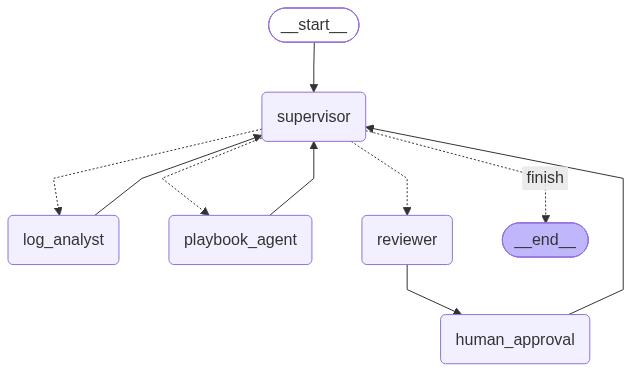

In [15]:
# Optional: the workflow as a picture
from IPython.display import Image, display
display(Image(team.get_graph().draw_mermaid_png()))

## Step 13: Run the team - live investigation

`stream_mode="updates"` shows each node as it finishes: watch the supervisor route,
the retry absorb the simulated timeout, the specialists report, and the run pause for approval.

In [18]:
QUESTION = ("Investigate host ENG-WS-07 between 01:30 and 02:30 on 2026-10-10. "
            "Build a timeline, check each event against the playbook, "
            "give a severity and next steps.")

config = {"configurable": {"thread_id": "incident-1"}}

for step in team.stream({"messages": [("user", QUESTION)]}, config, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"\n----- {node_name} -----")
        if node_name == "__interrupt__":
            print("PAUSED - the graph is waiting for a human decision")
        else:
            for key in ("log_findings", "playbook_findings", "report"):
                if update and update.get(key):
                    print(update[key][:800])

[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: True, approved: False -> next: reviewer

----- supervisor -----

----- reviewer -----
Incident Report: ENG-WS-07 on 2026-10-10 (01:30–02:30)

1. What happened (timeline with evidence):
- 01:41–01:46: Six consecutive failed login attempts for user svc_historian from external IP 45.155.205.99 using wrong passwords (Low severity initially).
- 01:52:05: Successful interactive login by svc_historian from same external IP 45.155.205.99 (Medium severity).
- 02:03:44: USB storage device mounted by svc_historian from internal IP 10.10.4.37 (Medium severity).

2. Playbook rules broken:
- Rule 2: More than five failed logins within 10 minutes for same account indicates suspected brute force; successful login after failed attempts elevates severity to High. Also, login from external IP to internal workstation raises severity by one level.
- Rule 5: USB storage devices are not allowed o

----- __interrupt__ -----
PA

In [19]:
# What is the graph waiting for?
state = team.get_state(config)
print("Next node to run:", state.next)
for task in state.tasks:
    for intr in task.interrupts:
        print("\nApproval request:", intr.value["instruction"])
        print("\nDRAFT REPORT:\n", intr.value["report"])

Next node to run: ('human_approval',)

Approval request: Review the report. Resume with 'approve' to accept it, or with feedback to send it back to the Reviewer.

DRAFT REPORT:
 Incident Report: ENG-WS-07 on 2026-10-10 (01:30–02:30)

1. What happened (timeline with evidence):
- 01:41–01:46: Six consecutive failed login attempts for user svc_historian from external IP 45.155.205.99 using wrong passwords (Low severity initially).
- 01:52:05: Successful interactive login by svc_historian from same external IP 45.155.205.99 (Medium severity).
- 02:03:44: USB storage device mounted by svc_historian from internal IP 10.10.4.37 (Medium severity).

2. Playbook rules broken:
- Rule 2: More than five failed logins within 10 minutes for same account indicates suspected brute force; successful login after failed attempts elevates severity to High. Also, login from external IP to internal workstation raises severity by one level.
- Rule 5: USB storage devices are not allowed on ENG-WS-* hosts; USB 

## Step 14: The human decides

The run is frozen at the approval gate. Two ways forward - try both (re-run the two cells above for a fresh pause).

In [20]:
# Option A: approve -> the report becomes final and the supervisor finishes the run
from langgraph.types import Command

for step in team.stream(Command(resume="approve"), config, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"----- {node_name} -----")

print("\nFINAL REPORT (approved):\n")
print(team.get_state(config).values["report"])

[human] report approved
----- human_approval -----
[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: True, approved: True -> next: reviewer
----- supervisor -----
----- reviewer -----
----- __interrupt__ -----

FINAL REPORT (approved):

Incident Report: ENG-WS-07 on 2026-10-10 (01:30–02:30)

1. What happened (timeline with evidence):
- 01:41–01:46: Six consecutive login_failed events for user svc_historian from external IP 45.155.205.99 with wrong password attempts, indicating possible brute force (Low severity per logs, but see rules).
- 01:52:05: Successful interactive login for svc_historian from same external IP 45.155.205.99 (Medium severity per logs).
- 02:03:44: USB storage device mounted by svc_historian from internal IP 10.10.4.37 (Medium severity).

2. Playbook rules broken:
- Rule 2: Six failed logins within 10 minutes meet brute force criteria; successful login after failed attempts indicates suspected credential compromise, raising severit

In [21]:
# Option B: send it back -> feedback goes to the Reviewer, the report is rewritten,
# and the graph pauses at the human gate again
from langgraph.types import Command

for step in team.stream(Command(resume="Severity must be Critical and name the OT on-call engineer explicitly."), config, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"----- {node_name} -----")

[human] sent back with feedback: Severity must be Critical and name the OT on-call engineer explicitly.
----- human_approval -----
[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: True, approved: False -> next: reviewer
----- supervisor -----
----- reviewer -----
----- __interrupt__ -----


## Step 15: Memory - the team remembers the investigation

Same `thread_id` = the team (and the saved state) remembers.
Notice the supervisor routes a rules-only follow-up straight to the Playbook Analyst.

In [22]:
for step in team.stream({"messages": [("user", "Which account did the attacker use, and is it allowed to log in interactively?")]},
                        config, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"----- {node_name} -----")
        if node_name == "__interrupt__":
            print("PAUSED - approve in the next cell")
        elif update and update.get("report"):
            print(update["report"][:600])

[supervisor] log_findings ready: False, playbook_findings ready: False, report ready: False, approved: False -> next: log_analyst
----- supervisor -----
----- log_analyst -----
[supervisor] log_findings ready: True, playbook_findings ready: False, report ready: False, approved: False -> next: playbook_agent
----- supervisor -----
----- playbook_agent -----
[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: False, approved: False -> next: reviewer
----- supervisor -----
----- reviewer -----
Incident Report:

1. What happened:
The investigation found no security log entries indicating which account the attacker used or whether that account is allowed to log in interactively. However, playbook analysis indicates the attacker used a service account (with a name starting with "svc_").

2. Which playbook rules were broken:
Rule 3 was violated: "Service accounts must never log in interactively." Any interactive login by a service account is considered High sev

In [23]:
# Approve the follow-up report too, to close the thread cleanly
from langgraph.types import Command
for step in team.stream(Command(resume="approve"), config, stream_mode="updates"):
    for node_name, update in step.items():
        print(f"----- {node_name} -----")

[human] report approved
----- human_approval -----
[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: True, approved: True -> next: finish
----- supervisor -----


## Step 16: One assistant vs a coordinated team - the comparison

Same question, both designs, side by side.

In [24]:
import time

def run_and_count(agent_or_graph, question, thread):
    cfg = {"configurable": {"thread_id": thread}}
    t0 = time.time()
    steps = 0
    for step in agent_or_graph.stream({"messages": [("user", question)]}, cfg, stream_mode="updates"):
        steps += len(step)
    return steps, time.time() - t0

q = "Investigate ENG-WS-07 on 2026-10-10 between 01:30 and 02:30. Severity and next steps?"

single_steps, single_t = run_and_count(single_agent, q, "compare-single")
print(f"MC13 single agent: {single_steps} model/tool steps in {single_t:.1f}s")

team_steps, team_t = run_and_count(team, q, "compare-team")
print(f"MC14 team: {team_steps} graph steps in {team_t:.1f}s (then it pauses for your approval)")

MC13 single agent: 5 model/tool steps in 4.2s
[supervisor] log_findings ready: False, playbook_findings ready: False, report ready: False, approved: False -> next: log_analyst
[supervisor] log_findings ready: True, playbook_findings ready: False, report ready: False, approved: False -> next: playbook_agent
[supervisor] log_findings ready: True, playbook_findings ready: True, report ready: False, approved: False -> next: reviewer
MC14 team: 7 graph steps in 8.5s (then it pauses for your approval)


In [25]:
from IPython.display import Markdown, display
display(Markdown("""
| | MC13: one assistant | MC14: a team |
|---|---|---|
| Who decides the steps | The model, inside one loop | You, in the graph (supervisor + edges) |
| Tool permissions | One agent holds ALL tools | Each specialist holds only its own |
| Fixed order of steps | Not guaranteed | Guaranteed by the edges |
| Retry on failure | The loop just fails | `RetryPolicy` retries one node |
| Human approval | Middleware on a tool | A full gate: pause, edit, re-route |
| Best for | Quick assistants, a few tools | Controlled multi-step workflows |
"""))


| | MC13: one assistant | MC14: a team |
|---|---|---|
| Who decides the steps | The model, inside one loop | You, in the graph (supervisor + edges) |
| Tool permissions | One agent holds ALL tools | Each specialist holds only its own |
| Fixed order of steps | Not guaranteed | Guaranteed by the edges |
| Retry on failure | The loop just fails | `RetryPolicy` retries one node |
| Human approval | Middleware on a tool | A full gate: pause, edit, re-route |
| Best for | Quick assistants, a few tools | Controlled multi-step workflows |


## Assignment

1. Add a third specialist: an **Asset Analyst** with a read-only `get_asset_info(host)` tool
   (owner, zone, criticality - build a small `assets` table like in MC13). Wire it into the graph
   and teach the supervisor when to call it.
2. Turn `SIMULATE_FAILURE` off and on. Where does the run change? What stays the same?
3. Send a report back twice with different feedback. How does the Reviewer's second draft differ?
4. **Stretch:** replace `InMemorySaver` with `SqliteSaver` so the investigation survives a kernel restart.